# NN_L14_chart_regime

**Market-stress detection on S&P 500 chart windows (120 trading days): logistic regression on numbers, logistic regression on CLIP image embeddings, CLIP zero-shot and Qwen2-VL zero-shot; ROC curves and AUC on 2019-2026, after Jheng, Pele, Tak and Găman (2026).**

Neural Networks and Deep Learning (NN), Lecture 14 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L14/NN_L14_chart_regime/NN_L14_chart_regime.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

AUC numeric = 0.933   [regime.numeric.auc]
average precision numeric = 0.578   [regime.numeric.ap]
AUC clip_probe = 0.88   [regime.clip_probe.auc]
average precision clip_probe = 0.449   [regime.clip_probe.ap]
AUC clip_zs = 0.907   [regime.clip_zs.auc]
average precision clip_zs = 0.605   [regime.clip_zs.ap]
AUC vlm_zs = 0.758   [regime.vlm_zs.auc]
average precision vlm_zs = 0.302   [regime.vlm_zs.ap]
stress share in the test windows (%) = 8.4   [charts_task.base_test]


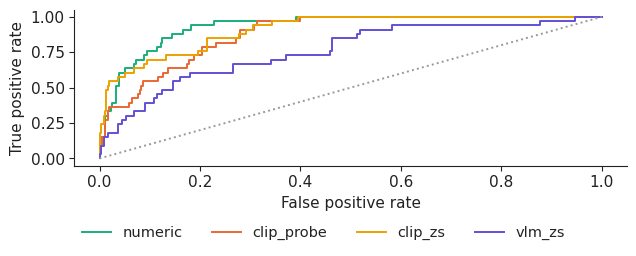

In [3]:
RES = REPO + 'lectures/L14/results/'
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
C = pd.read_csv(RES + 'chart_regime.csv')
T = C[C.split == 'test']
S = {'numeric': T.numeric, 'clip_probe': T.clip_probe, 'clip_zs': T.clip_zs, 'vlm_zs': T.vlm_stress}
for k, s in S.items():
    show(f'regime.{k}.auc', f'AUC {k}', round(float(roc_auc_score(T.stress, s)), 3))
    show(f'regime.{k}.ap', f'average precision {k}', round(float(average_precision_score(T.stress, s)), 3))
show('charts_task.base_test', 'stress share in the test windows (%)', round(100 * float(T.stress.mean()), 1))
fig, ax = plt.subplots(figsize=(6.4, 2.6))
for (k, s), c in zip(S.items(), [PAL['benchmark'], PAL['model'], PAL['alt'], '#6250d6']):
    fpr, tpr, _ = roc_curve(T.stress, s)
    ax.plot(fpr, tpr, color=c, label=k)
ax.plot([0, 1], [0, 1], ls=':', color='#999999')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
legend_bottom(fig)
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig('chart_regime.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()